# Hałda węgla — objętość w czasie
Obwałowany plac z czarnym materiałem (węgiel / odpady węglowe) przy zakładzie przeróbczym kopalni odkrywkowej. Nazwa i położenie celowo zamaskowane — mapy mają współrzędne w km od punktu hałdy.

| źródło | co mierzy | okres |
|---|---|---|
| SRTM, ALOS AW3D30, Copernicus DEM | **wysokość** hałdy nad terenem sprzed jej powstania | 2000, ~2008, ~2012 |
| Sentinel-1 RTC | **zmianę wysokości** z przesunięcia geokodowania (radargrametria) | 2016Q3–2026Q3 |
| Sentinel-2 L2A | **zasięg** czarnego materiału i wody, tekstura do 3D | 2016Q3–2026Q3 |

In [1]:
import json, pandas as pd
s = json.load(open('out/halda/halda_podsumowanie.json', encoding='utf-8'))
d = pd.DataFrame(s['dem'])
pd.Series({
  'powierzchnia hałdy [ha]': round(s['powierzchnia_km2'] * 100),
  'objętość ~2008 [mln m³] (DEM)': round(d.objetosc_Mm3[1], 1),
  'objętość ~2012 [mln m³] (DEM)': round(d.objetosc_Mm3[2], 1),
  'średnia wysokość ~2012 [m]': round(d.sr_wys_m[2], 1),
  'trend wysokości 2016–2026 [m/rok] (S1)': f"{s['s1_trend_m_rok']:+.2f} ± {s['s1_trend_se_m_rok']:.2f}",
  'trend objętości 2016–2026 [mln m³/rok]': f"{s['s1_trend_m_rok'] * s['powierzchnia_km2']:+.3f} ± {s['s1_trend_se_m_rok'] * s['powierzchnia_km2']:.3f}",
  'szum S1 na kwartał [m]': round(s['s1_sigma_m_kwartal'], 1),
  'czułość metody (test wstrzyknięcia)': round(s['czulosc_metody'], 2),
}).to_frame('wartość')

,wartość
powierzchnia hałdy [ha],49
objętość ~2008 [mln m³] (DEM),3.8
objętość ~2012 [mln m³] (DEM),5.6
średnia wysokość ~2012 [m],11.6
trend wysokości 2016–2026 [m/rok] (S1),+0.09 ± 0.10
trend objętości 2016–2026 [mln m³/rok],+0.045 ± 0.050
szum S1 na kwartał [m],1.9
czułość metody (test wstrzyknięcia),0.79


## 1. Obrys hałdy (Sentinel-2)
Węgiel ma płaskie, niskie widmo (NIR < 0,10, czerwony < 0,09); woda też jest ciemna, ale nie w SWIR (B11 < 0,04) — tak się je rozdziela. Obrys = obszar czarny w ≥ 30% kwartałów, spójny z punktem; stawy osadowe za wałem są poza nim.

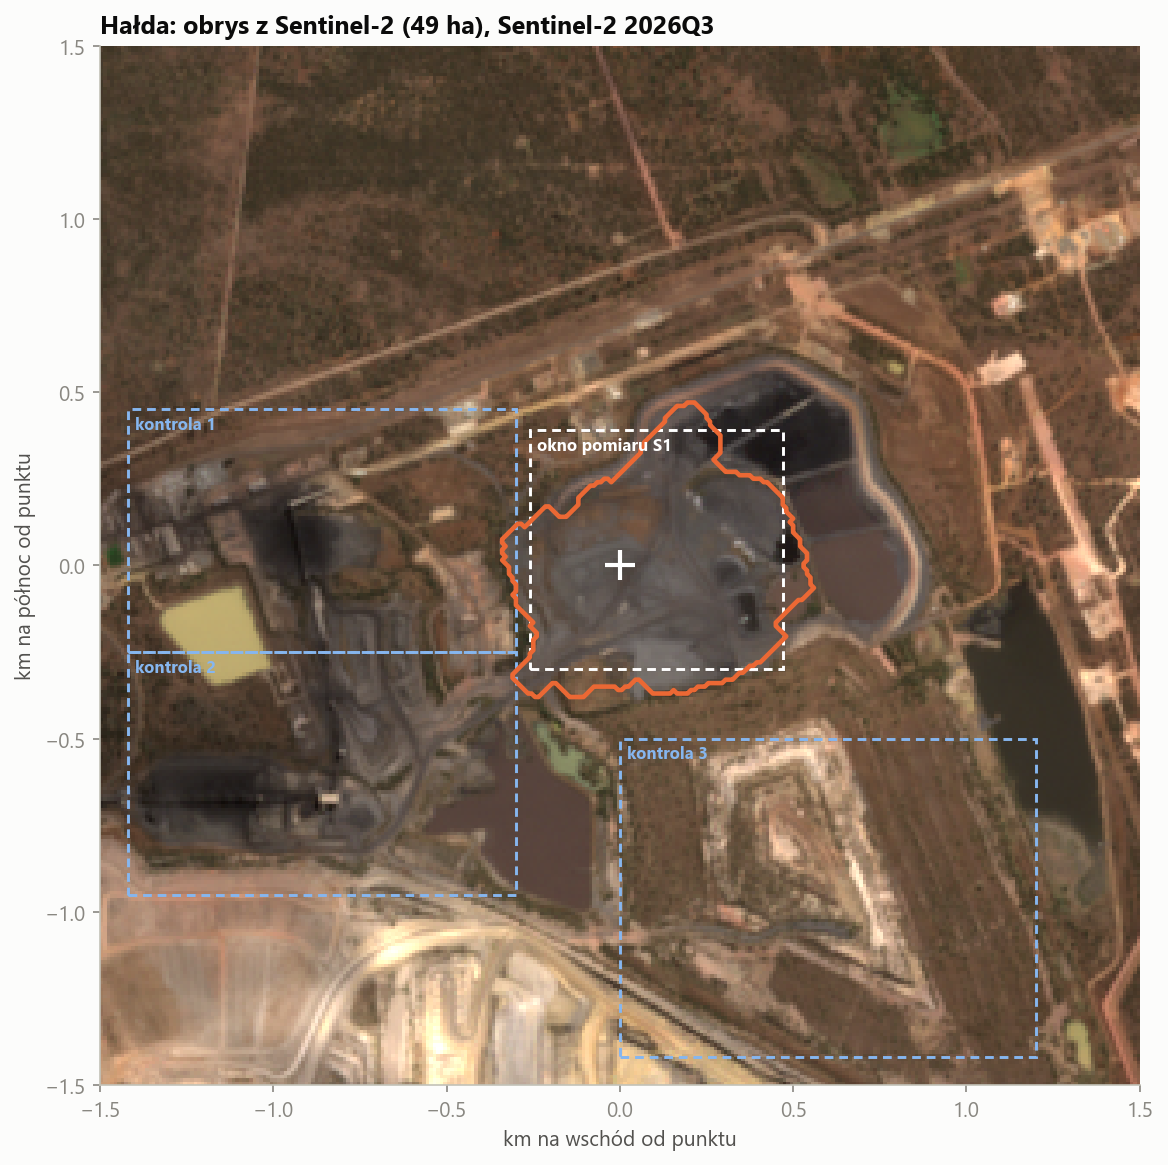

In [2]:
from IPython.display import Image, display
display(Image(filename='out/halda/h01_mapa.png', width=1050))

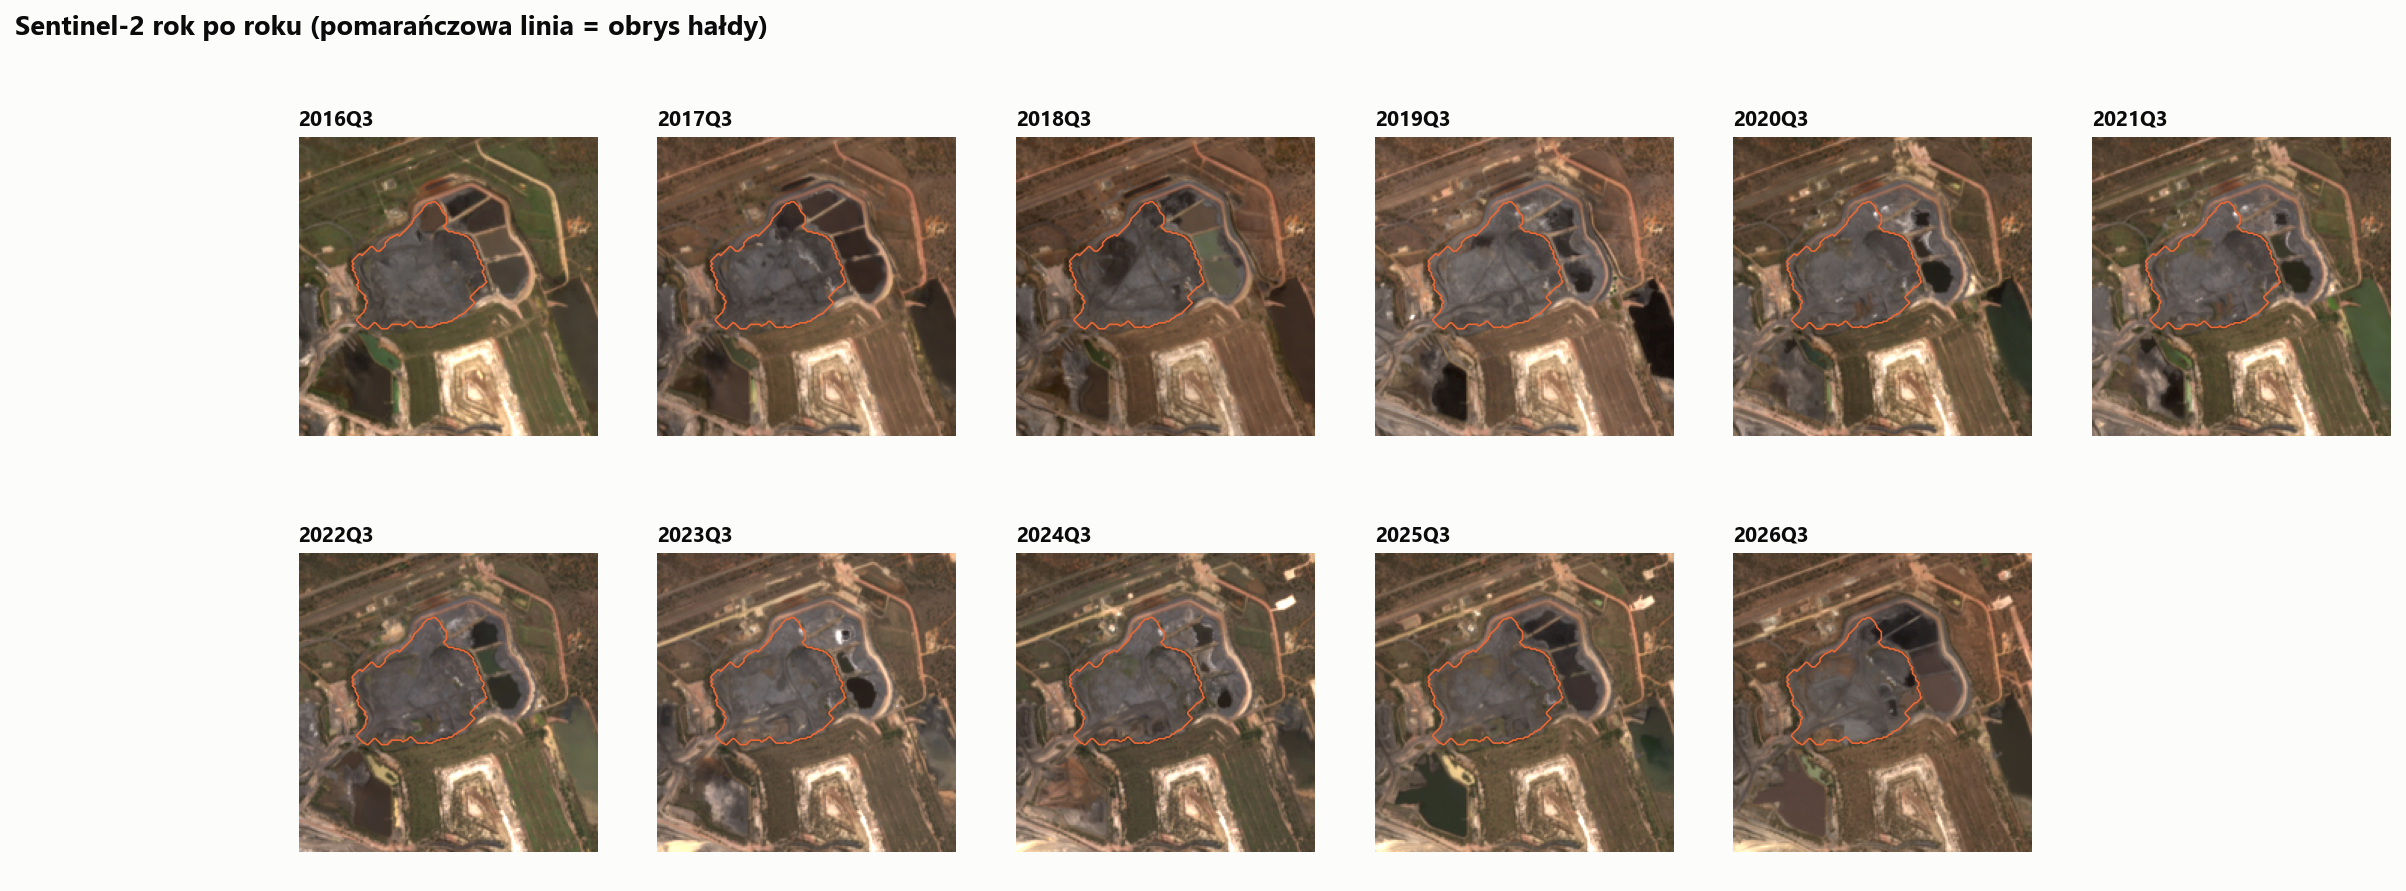

In [3]:
from IPython.display import Image, display
display(Image(filename='out/halda/h05_mozaika_s2.png', width=1050))

## 2. Zmierzona historia: trzy DEM-y
W lutym 2000 r. był tu płaski step. Wysokość hałdy = DEM epoki − SRTM, po wyrównaniu pionowym na stabilnym terenie (rozrzut 1,3–1,7 m).

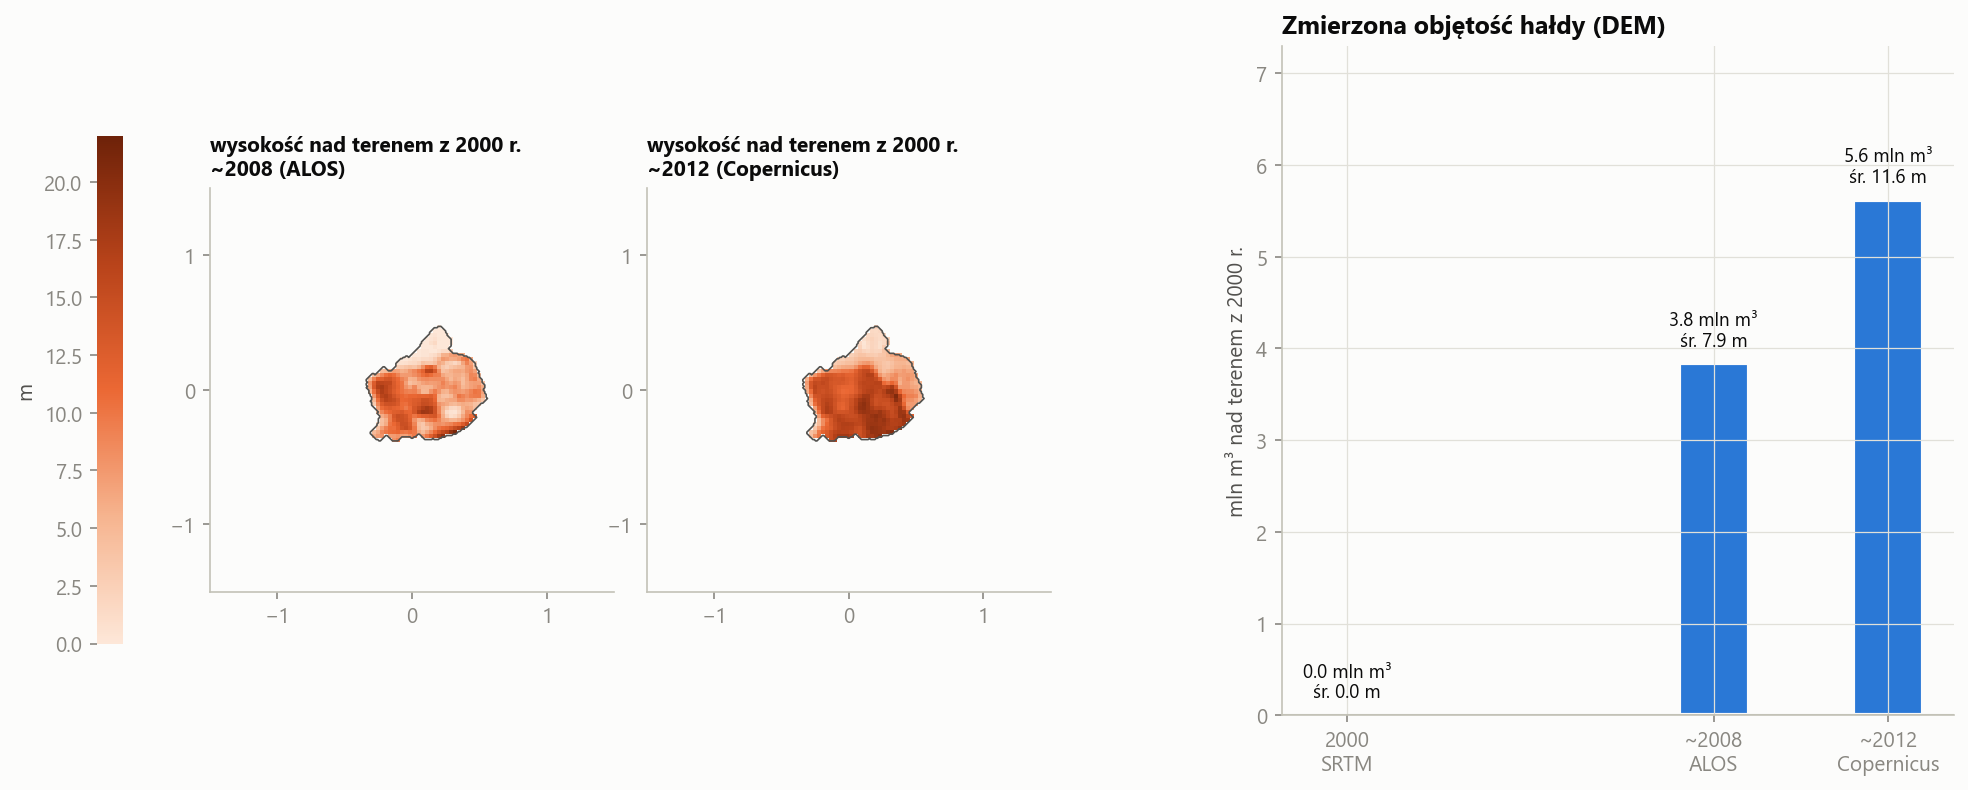

In [4]:
from IPython.display import Image, display
display(Image(filename='out/halda/h02_dem_historia.png', width=1050))

## 3. Sentinel-1: wysokość po 2016 r. (radargrametria z geokodowania)
Sceny RTC są geokodowane Copernicus DEM (~2012). Punkt wyższy niż w DEM o Δh leży bliżej satelity, niż zakłada geokodowanie, więc na obrazie przesuwa się w stronę satelity o **Δh · ctg θ** (θ = 38,2° z adnotacji sceny, kierunek ESE). Przesunięcie mierzone:

* **znormalizowaną korelacją** w zakresie ±60 m z paraboliczną precyzją podpikselową,
* w **sieci par** kwartałów odległych o 1–4 kwartały (tekstura hałdy zmienia się po zwałowaniu — porównanie z rokiem 2016 traci korelację), z inwersją najmniejszych kwadratów jak w SBAS,
* **względem mediany trzech stabilnych okien** — wszystkie okna przesuwają się wspólnie o ~8 m między 2016Q3 a 2017Q3 (zmiana geolokacji S1, nie terenu); mediana jest odporna na okno, które samo się zmienia.

Szum = rozrzut okien kontrolnych. Czułość sprawdzona **wstrzyknięciem** znanego skoku wysokości do prawdziwych obrazów (±3 m, +6 m) — metoda odzyskuje go z właściwym znakiem i bez fałszywego sygnału przed skokiem; niedoszacowanie (okno obejmuje nieruchome brzegi) jest skalibrowane.

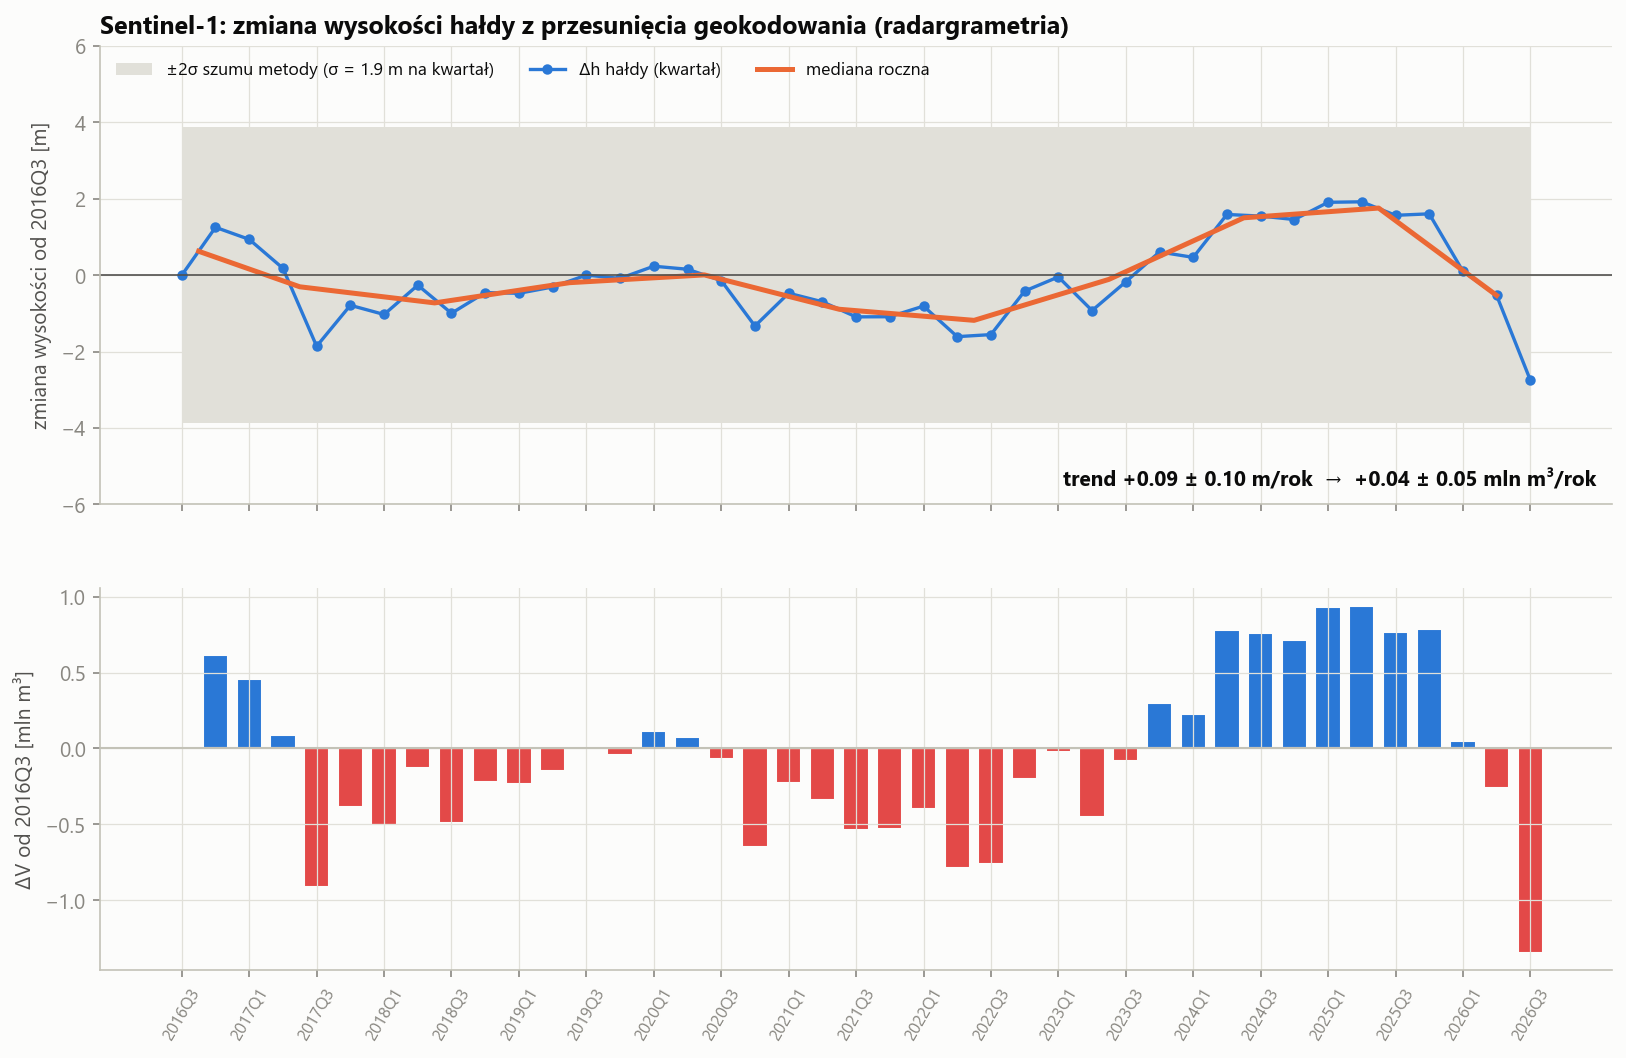

In [5]:
from IPython.display import Image, display
display(Image(filename='out/halda/h03_wysokosc_s1.png', width=1050))

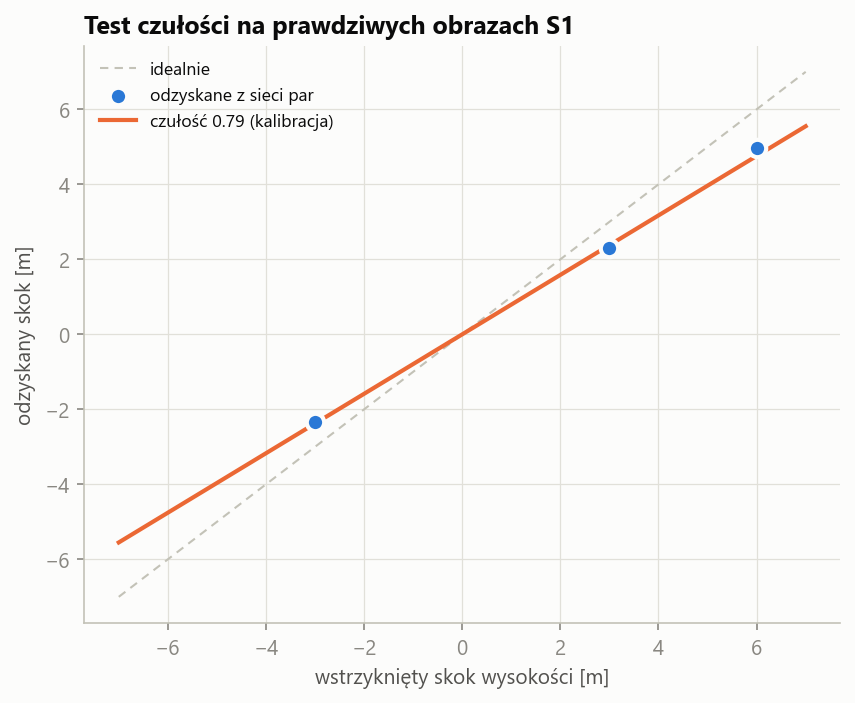

In [6]:
from IPython.display import Image, display
display(Image(filename='out/halda/h06_test_czulosci.png', width=1050))

## 4. Pokrycie i aktywność

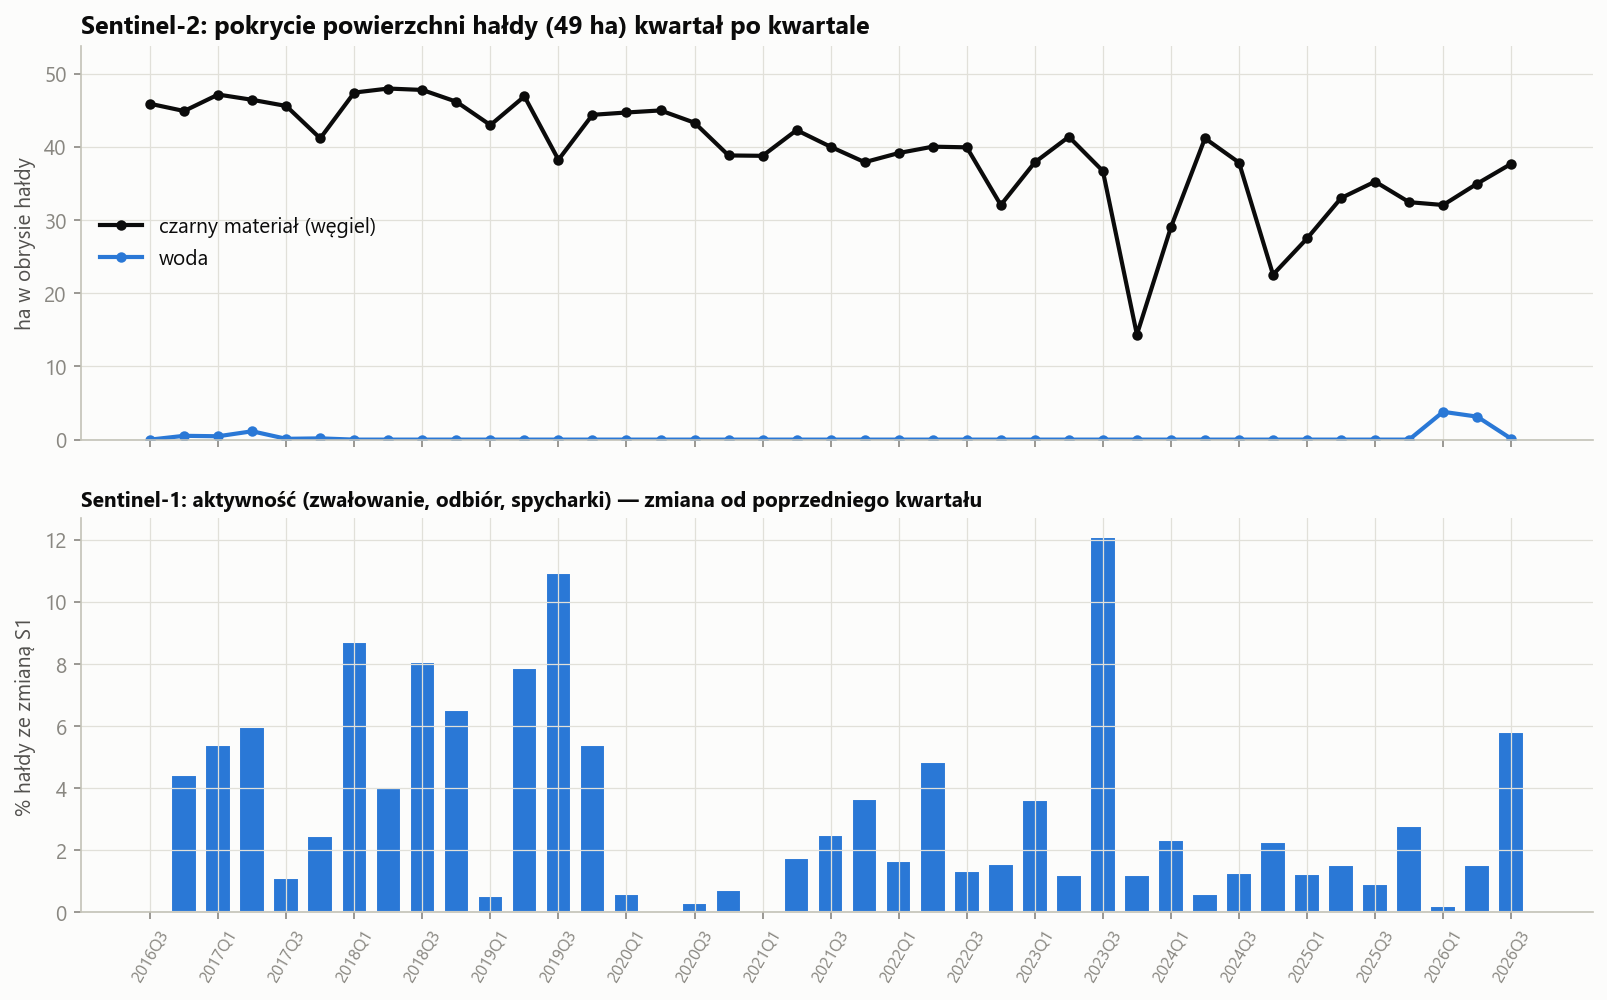

In [7]:
from IPython.display import Image, display
display(Image(filename='out/halda/h04_pokrycie_aktywnosc.png', width=1050))

In [8]:
pd.read_csv('out/halda/halda_kwartalnie.csv').round(2)

,kwartal,n_scen,wegiel_ha,woda_ha,jasnosc,dh_m,dv_Mm3,dv_sigma_Mm3,aktywnosc_proc,rok
0,2016Q3,7,45.88,0.00,0.06,-0.00,-0.00,0.95,NaN,2016
1,2016Q4,4,44.89,0.52,0.07,1.25,0.61,0.95,4.42,2016
2,2017Q1,3,47.14,0.46,0.06,0.94,0.46,0.95,5.38,2017
3,2017Q2,5,46.42,1.14,0.05,0.18,0.09,0.95,5.97,2017
4,2017Q3,16,45.58,0.11,0.06,-1.86,-0.91,0.95,1.08,2017
5,2017Q4,6,41.16,0.17,0.07,-0.79,-0.39,0.95,2.45,2017
6,2018Q1,7,47.41,0.00,0.06,-1.03,-0.50,0.95,8.71,2018
7,2018Q2,13,47.96,0.00,0.05,-0.26,-0.13,0.95,4.01,2018
8,2018Q3,17,47.77,0.00,0.05,-1.00,-0.49,0.95,8.06,2018
9,2018Q4,12,46.16,0.00,0.07,-0.45,-0.22,0.95,6.50,2018


## 5. 3D
`out/halda/halda_3d.html` — jeden plik (three.js), otwiera się z dysku. Klatki: 2000 → ~2008 → ~2012 (DEM) i kwartały 2016Q3–2026Q3 (Copernicus DEM + Δh z S1, tekstura S2). ←/→, spacja.

## Ograniczenia
* **Luka 2012 → 2016Q3** — żaden darmowy pomiar wysokości jej nie pokrywa; szereg S1 jest względny (od 2016Q3), a nie bezwzględny.
* S1 mierzy **średnią** zmianę wysokości w oknie hałdy; lokalne przerzuty wewnątrz (tu wybrane, tam dosypane) znoszą się i nie są widoczne.
* Szum ~2 m na kwartał → wykrywalna zmiana roczna rzędu 2 m, czyli ~1 mln m³ na tej powierzchni.
* Ostatnie kwartały szeregu mają mniej par w sieci, więc są słabiej związane.
* Optyka nie odróżni węgla handlowego od odpadów węglowych — oba są czarne.